# Questão 3 – Spark, MinIO e Benchmark de Formatos

## a) Rede e bucket `datalake`

In [8]:
import socket
print("minio resolve para:", socket.gethostbyname("minio"))
print("este container (spark):", socket.gethostbyname(socket.gethostname()))

minio resolve para: 172.20.0.2
este container (spark): 172.20.0.5


In [9]:
import os
import boto3
from botocore.client import Config

# Bucket de destino 
BUCKET = "datalake"

# Credenciais lidas do ambiente do contêiner (spark/.env), fora do código
MINIO_USER = os.getenv("MINIO_USER")
MINIO_PASS = os.getenv("MINIO_PASS")

s3 = boto3.client(
    "s3",
    endpoint_url="http://minio:9000",
    aws_access_key_id=MINIO_USER,
    aws_secret_access_key=MINIO_PASS,
    config=Config(signature_version="s3v4"),
    region_name="us-east-1",
)

if BUCKET not in [b["Name"] for b in s3.list_buckets()["Buckets"]]:
    s3.create_bucket(Bucket=BUCKET)
print("Buckets:", [b["Name"] for b in s3.list_buckets()["Buckets"]])

Buckets: ['datalake', 'datalake-bronze', 'datalake-gold', 'datalake-meta', 'datalake-silver', 'meu-bucket', 'meu-novo-bucket']


## b) Escrita, leitura e tamanho por formato

In [10]:
import time, os, json
from pyspark.sql import SparkSession

# Credenciais lidas do ambiente do contêiner (spark/.env), fora do código
MINIO_USER = os.getenv("MINIO_USER")
MINIO_PASS = os.getenv("MINIO_PASS")

# =====================================================
# Sessão Spark
# =====================================================
spark = (
    SparkSession.builder
    .appName("Benchmark-Formats")
    .master("local[*]")
    .config("spark.executor.memory", "1g")
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
    .config("spark.hadoop.fs.s3a.path.style.access", "true")
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "true")
    .config("spark.hadoop.fs.s3a.endpoint", "http://minio:9000")
    .config("spark.hadoop.fs.s3a.access.key", MINIO_USER)
    .config("spark.hadoop.fs.s3a.secret.key", MINIO_PASS)
    .config("spark.hadoop.fs.s3a.committer.name", "directory")
    .getOrCreate()
)
sc = spark.sparkContext
sc.setLogLevel("ERROR")

# =====================================================
# Dataset base (local CSV)
# =====================================================
schema = "raceId INT, driverId INT, lap INT, position INT, time STRING, milliseconds INT"
df = spark.read.csv("/home/jovyan/data/lap_times.csv", header=True, schema=schema)
print("Linhas carregadas:", df.count())

# =====================================================
# Funções auxiliares
# =====================================================
def medir_tempo(op, label):
    inicio = time.time()
    result = op()
    fim = time.time()
    print(f"{label}: {fim - inicio:.2f}s")
    return fim - inicio, result

def medir_leitura(fmt, path):
    inicio = time.time()
    if fmt == "csv":
        df = spark.read.option("header", True).csv(path)
    elif fmt == "json":
        df = spark.read.json(path)
    elif fmt == "parquet":
        df = spark.read.parquet(path)
    elif fmt == "avro":
        df = spark.read.format("avro").option("ignoreExtension", "true").load(path)
    elif fmt == "orc":
        df = spark.read.orc(path)
    linhas = df.count()
    fim = time.time()
    return fim - inicio, linhas

# =====================================================
# Escrita em diferentes formatos no MinIO
# =====================================================
base = "s3a://datalake/lap_times_"
formats = ["csv", "json", "parquet", "avro", "orc"]
tempos_escrita = {}
for fmt in formats:
    path = base + fmt
    print(f"Gravando {fmt.upper()} -> {path}")
    inicio = time.time()
    if fmt == "csv":
        df.write.mode("overwrite").option("header", True).csv(path)
    elif fmt == "json":
        df.write.mode("overwrite").json(path)
    elif fmt == "parquet":
        df.write.mode("overwrite").parquet(path)
    elif fmt == "avro":
        df.write.mode("overwrite").format("avro").save(path)
    elif fmt == "orc":
        df.write.mode("overwrite").orc(path)
    fim = time.time()
    tempos_escrita[fmt] = round(fim - inicio, 2)
    print(f"→ Tempo de escrita {fmt.upper()}: {tempos_escrita[fmt]}s")

# =====================================================
# Verifica tamanhos com mc (precisa alias 'local')
# =====================================================
!mc alias set local http://minio:9000 $MINIO_USER $MINIO_PASS >/dev/null
tamanhos = {}
for fmt in formats:
    info = os.popen(f"mc du --json local/datalake/lap_times_{fmt}/").read()
    try:
        tamanho = float(json.loads(info)["size"]) / (1024 * 1024)
    except:
        tamanho = 0
    tamanhos[fmt] = round(tamanho, 2)

# =====================================================
# Leitura e benchmark
# =====================================================
tempos_leitura = {}
linhas_lidas = {}
for fmt in formats:
    path = base + fmt
    try:
        tempo, linhas = medir_leitura(fmt, path)
        tempos_leitura[fmt] = round(tempo, 2)
        linhas_lidas[fmt] = linhas
        print(f"{fmt.upper()}: {linhas} linhas em {tempo:.2f}s")
    except Exception as e:
        tempos_leitura[fmt] = None
        linhas_lidas[fmt] = 0
        print(f"Erro ao ler {fmt}: {e}")

# =====================================================
# Resultado consolidado
# =====================================================
print("\n=== RESULTADO FINAL ===")
print(f"{'Formato':<10} {'Tamanho (MB)':>12} {'Escrita (s)':>12} {'Leitura (s)':>12} {'Linhas':>10}")
for fmt in formats:
    print(f"{fmt.upper():<10} {tamanhos[fmt]:>12.2f} {tempos_escrita[fmt]:>12.2f} {tempos_leitura[fmt] or 0:>12.2f} {linhas_lidas[fmt]:>10}")


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/04 10:40:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Linhas carregadas: 551742
Gravando CSV -> s3a://datalake/lap_times_csv


→ Tempo de escrita CSV: 4.83s
Gravando JSON -> s3a://datalake/lap_times_json


→ Tempo de escrita JSON: 1.3s
Gravando PARQUET -> s3a://datalake/lap_times_parquet


→ Tempo de escrita PARQUET: 3.68s
Gravando AVRO -> s3a://datalake/lap_times_avro


→ Tempo de escrita AVRO: 1.6s
Gravando ORC -> s3a://datalake/lap_times_orc


→ Tempo de escrita ORC: 2.07s


CSV: 551742 linhas em 3.42s


JSON: 551742 linhas em 2.42s
PARQUET: 551742 linhas em 0.63s


AVRO: 551742 linhas em 1.13s
ORC: 551742 linhas em 0.38s

=== RESULTADO FINAL ===
Formato    Tamanho (MB)  Escrita (s)  Leitura (s)     Linhas
CSV               14.65         4.83         3.42     551742
JSON              47.80         1.30         2.42     551742
PARQUET            4.37         3.68         0.63     551742
AVRO               7.34         1.60         1.13     551742
ORC                4.19         2.07         0.38     551742


## c) Comparativo em tabela e gráficos

,Formato,Tamanho (MB),Escrita (s),Leitura (s)
0,CSV,14.65,4.83,3.42
1,JSON,47.80,1.30,2.42
2,PARQUET,4.37,3.68,0.63
3,AVRO,7.34,1.60,1.13
4,ORC,4.19,2.07,0.38


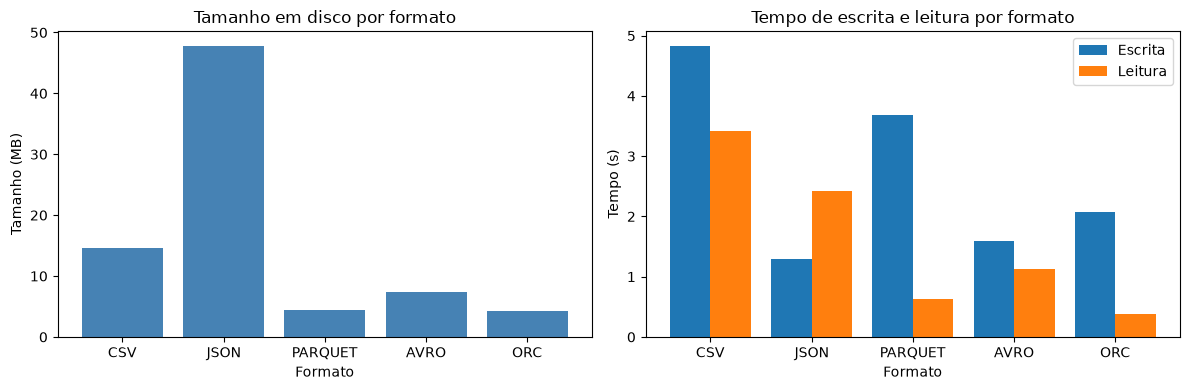

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Valores medidos neste notebook (variáveis da célula do benchmark)
resultado = pd.DataFrame({
    "Formato": [f.upper() for f in formats],
    "Tamanho (MB)": [tamanhos[f] for f in formats],
    "Escrita (s)": [tempos_escrita[f] for f in formats],
    "Leitura (s)": [tempos_leitura[f] for f in formats],
})
display(resultado)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(resultado["Formato"], resultado["Tamanho (MB)"], color="steelblue")
ax1.set_title("Tamanho em disco por formato")
ax1.set_xlabel("Formato")
ax1.set_ylabel("Tamanho (MB)")

x = range(len(resultado))
ax2.bar([i - 0.2 for i in x], resultado["Escrita (s)"], width=0.4, label="Escrita")
ax2.bar([i + 0.2 for i in x], resultado["Leitura (s)"], width=0.4, label="Leitura")
ax2.set_xticks(list(x), resultado["Formato"])
ax2.set_title("Tempo de escrita e leitura por formato")
ax2.set_xlabel("Formato")
ax2.set_ylabel("Tempo (s)")
ax2.legend()

plt.tight_layout()
plt.show()

## d) Discussão: OLAP vs. streaming

**Tamanho.** Tanto o ORC (4,19 MB) quanto o Parquet (4,37 MB) guardam os dados de forma colunar. Quando valores se repetem, eles registram a ocorrência de um determinado valor em vez de repeti-lo (*run-length encoding*), além de usarem dicionário e compressão. Isso gera um arquivo final com um número menor de bytes, guardando a mesma quantidade de dados de forma lógica. O CSV (14,65 MB) e o JSON (47,80 MB) são texto, linha a linha. O JSON é ainda maior que o CSV porque, apesar de ter vantagens, é baseado em chave-valor e repete o nome das chaves a cada ocorrência.

**Leitura.** ORC (0,38 s) e Parquet (0,63 s) foram os mais rápidos porque, além de armazenarem as colunas de forma vetorial, quando consultados acessam apenas as colunas necessárias à consulta, podendo até entregar apenas parte do arquivo quando requisitados no object storage (MinIO), sem precisar interpretar texto como CSV e JSON.

**OLAP.** Para workloads analíticos, Parquet e ORC são os mais adequados, pelos dois pontos acima: ocupam menos espaço e leem só o que a consulta precisa.

**Streaming.** Para ingestão contínua, o Avro é o mais indicado. Ele é orientado a linha, então cada registro é anexado inteiro, sem reorganizar colunas, e o esquema vai junto no arquivo, aceitando evolução (campos novos sem quebrar quem lê), sendo o padrão em Kafka. No benchmark ele teve escrita rápida (1,60 s) e tamanho intermediário (7,34 MB).

**Observação.** Os tempos variaram a cada execução, talvez pelo tamanho do dataset é pequeno (~550 mil linhas) e por rodar localmente. O CSV, por ser o primeiro gravado, pode "pagar" pelo o aquecimento do Spark e da conexão com o MinIO. Tamanho pode ser uma métrica mais confiável. Ainda assim, faz sentido que Parquet e ORC tenham escrito mais devagar que o JSON ou Avro, por gastar mais tempo codificando na gravação, com objetivo de otimizar a leitura. 